<a href="https://colab.research.google.com/github/EduardoKenzoHayashi/gauss-seidel/blob/main/Gauss_Seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Número de iterações: 6
Solução aproximada: x = 1.00000003, y = 1.99999998, z = -1.00000001

  k       x(k)      y(k)        z(k)  ||x(k)-x(k-1)||_inf
 0          0         0           0                  NaN
 1        0.6 2.0545455 -0.91454545            2.0545455
 2 0.98836364 2.0067107 -0.99700165           0.38836364
 3  1.0000714 2.0002791 -0.99998637          0.011707769
 4  1.0000252 2.0000035  -1.0000047        0.00027554041
 5  1.0000013 1.9999997  -1.0000003        2.3892165e-05
 6          1         2          -1        1.2626069e-06


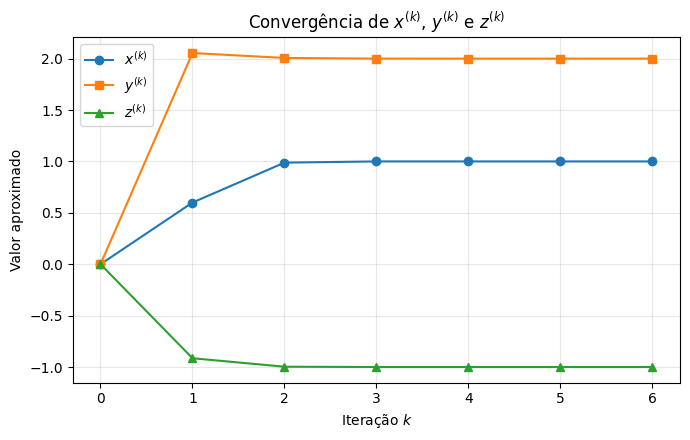

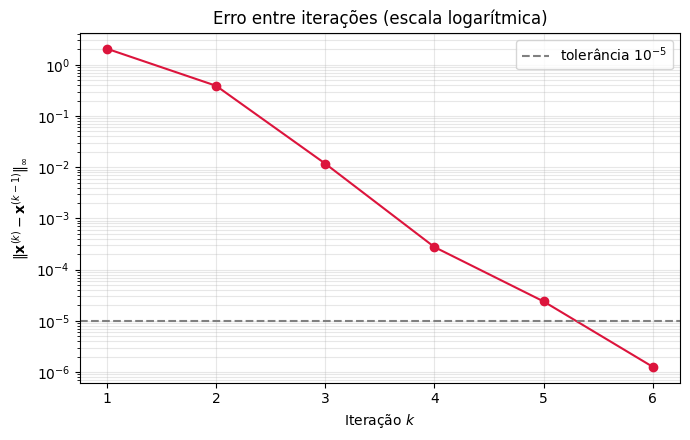

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Sistema do enunciado:
#   10x -  y + 2z =   6
#   -x + 11y -  z =  22
#   2x -  y + 10z = -10
# (estritamente diagonal dominante -> Gauss-Seidel converge)
# ============================================================
A = np.array([[10.0, -1.0,  2.0],
              [-1.0, 11.0, -1.0],
              [ 2.0, -1.0, 10.0]])
b = np.array([6.0, 22.0, -10.0])
x0 = np.zeros(len(b))          # x^(0) = (0, 0, 0)
tol = 1e-5
max_iter = 1000


def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):
    n = len(b)
    x = x0.astype(float).copy()
    historico = [(0, *x, np.nan)]   # (k, x, y, z, erro)
    for k in range(1, max_iter + 1):
        x_old = x.copy()
        for i in range(n):
            soma1 = A[i, :i] @ x[:i]              # já atualizados (k)
            soma2 = A[i, i + 1:] @ x_old[i + 1:]  # ainda da iteração (k-1)
            x[i] = (b[i] - soma1 - soma2) / A[i, i]
        erro = np.max(np.abs(x - x_old))          # norma infinito
        historico.append((k, *x, erro))
        if erro < tol:
            return x, k, historico
    return x, max_iter, historico


sol, iters, hist = gauss_seidel(A, b, x0, tol, max_iter)

# ---------------- Item 5: resultados ----------------
print(f"Número de iterações: {iters}")
print(f"Solução aproximada: x = {sol[0]:.8f}, y = {sol[1]:.8f}, z = {sol[2]:.8f}")

# ---------------- Item 6: tabela ----------------
df = pd.DataFrame(hist, columns=["k", "x(k)", "y(k)", "z(k)", "||x(k)-x(k-1)||_inf"])
df["k"] = df["k"].astype(int)
pd.set_option("display.float_format", lambda v: f"{v:.8g}")
print("\n", df.to_string(index=False))
df.to_csv("tabela_iteracoes.csv", index=False)

# ---------------- Item 7a: x, y, z em função de k ----------------
plt.figure(figsize=(7, 4.5))
plt.plot(df["k"], df["x(k)"], "o-", label="$x^{(k)}$")
plt.plot(df["k"], df["y(k)"], "s-", label="$y^{(k)}$")
plt.plot(df["k"], df["z(k)"], "^-", label="$z^{(k)}$")
plt.xlabel("Iteração $k$")
plt.ylabel("Valor aproximado")
plt.title("Convergência de $x^{(k)}$, $y^{(k)}$ e $z^{(k)}$")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafico_variaveis.png", dpi=200)

# ---------------- Item 7b: erro em escala log ----------------
plt.figure(figsize=(7, 4.5))
plt.semilogy(df["k"][1:], df["||x(k)-x(k-1)||_inf"][1:], "o-", color="crimson")
plt.axhline(tol, color="gray", ls="--", label=r"tolerância $10^{-5}$")
plt.xlabel("Iteração $k$")
plt.ylabel(r"$\|\mathbf{x}^{(k)}-\mathbf{x}^{(k-1)}\|_\infty$")
plt.title("Erro entre iterações (escala logarítmica)")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.savefig("grafico_erro.png", dpi=200)
plt.show()